In [98]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries ready!")

Libraries ready!


In [99]:

url = "https://raw.githubusercontent.com/justmarkham/scikit-learn-videos/master/data/Advertising.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (200, 5)


,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


In [100]:
print("📊 DATASET OVERVIEW")
print("=" * 45)

print("Dataset shape:", df.shape)

print("\n📌 Column names:")
print(df.columns.tolist())

print("\n🔍 Missing values:")
print(df.isnull().sum())

print("\n📈 Statistical summary:")
display(df.describe().round(2))

print("\n👀 First 5 rows:")
display(df.head())

📊 DATASET OVERVIEW
Dataset shape: (200, 5)

📌 Column names:
['Unnamed: 0', 'TV', 'Radio', 'Newspaper', 'Sales']

🔍 Missing values:
Unnamed: 0    0
TV            0
Radio         0
Newspaper     0
Sales         0
dtype: int64

📈 Statistical summary:


,Unnamed: 0,TV,Radio,Newspaper,Sales
count,200.00,200.00,200.00,200.00,200.00
mean,100.50,147.04,23.26,30.55,14.02
std,57.88,85.85,14.85,21.78,5.22
min,1.00,0.70,0.00,0.30,1.60
25%,50.75,74.38,9.98,12.75,10.38
50%,100.50,149.75,22.90,25.75,12.90
75%,150.25,218.82,36.52,45.10,17.40
max,200.00,296.40,49.60,114.00,27.00



👀 First 5 rows:


,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


In [101]:

from IPython.display import display, HTML

# Dashboard title
display(HTML("""
<div style="background:linear-gradient(135deg,#102A43,#2563EB);
padding:28px;border-radius:16px;color:white;font-family:Arial;
margin-bottom:18px;">
<h1 style="margin:0;">📊 Sales Prediction Dashboard</h1>
<p style="margin:10px 0 0;font-size:16px;">
INFOZATECH | Advertising Analytics & Machine Learning
</p>
</div>
"""))

# Summary cards
cards = [
    ("📁 Dataset Records", f"{len(df):,}", "#2563EB"),
    ("📌 Features", str(len(df.columns)), "#0D9488"),
    ("⚠️ Missing Values", str(int(df.isnull().sum().sum())), "#D97706"),
    ("💰 Average Sales", f"{df['Sales'].mean():.2f}", "#7C3AED")
]

html = '<div style="display:flex;flex-wrap:wrap;gap:14px;">'

for title, value, color in cards:
    html += f"""
    <div style="flex:1;min-width:150px;background:#F1F5F9;
    border-left:5px solid {color};border-radius:12px;padding:18px;
    font-family:Arial;">
        <div style="font-size:14px;color:#475569;">{title}</div>
        <div style="font-size:27px;font-weight:bold;
        color:{color};margin-top:8px;">{value}</div>
    </div>
    """

html += "</div>"
display(HTML(html))

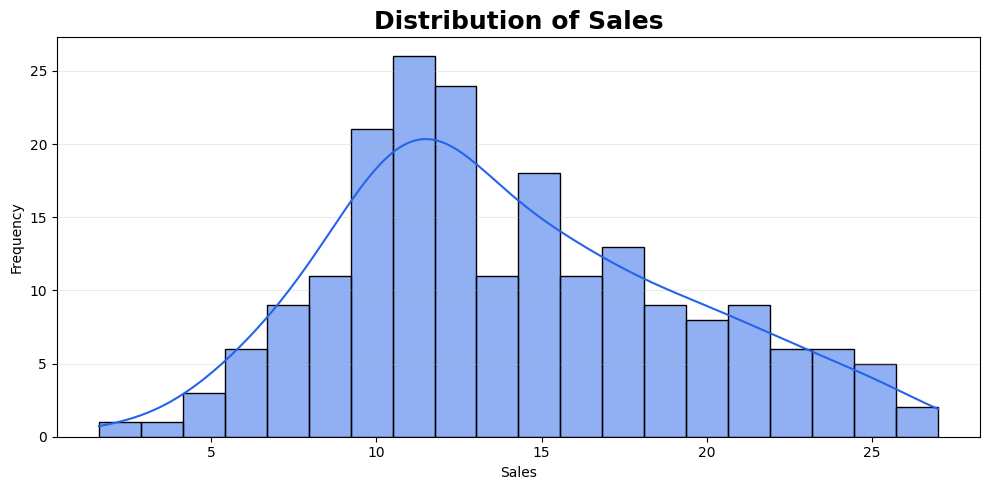

In [102]:

# SALES DISTRIBUTION

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Sales",
    bins=20,
    kde=True,
    color="#2563EB"
)

plt.title("Distribution of Sales", fontsize=18, fontweight="bold")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

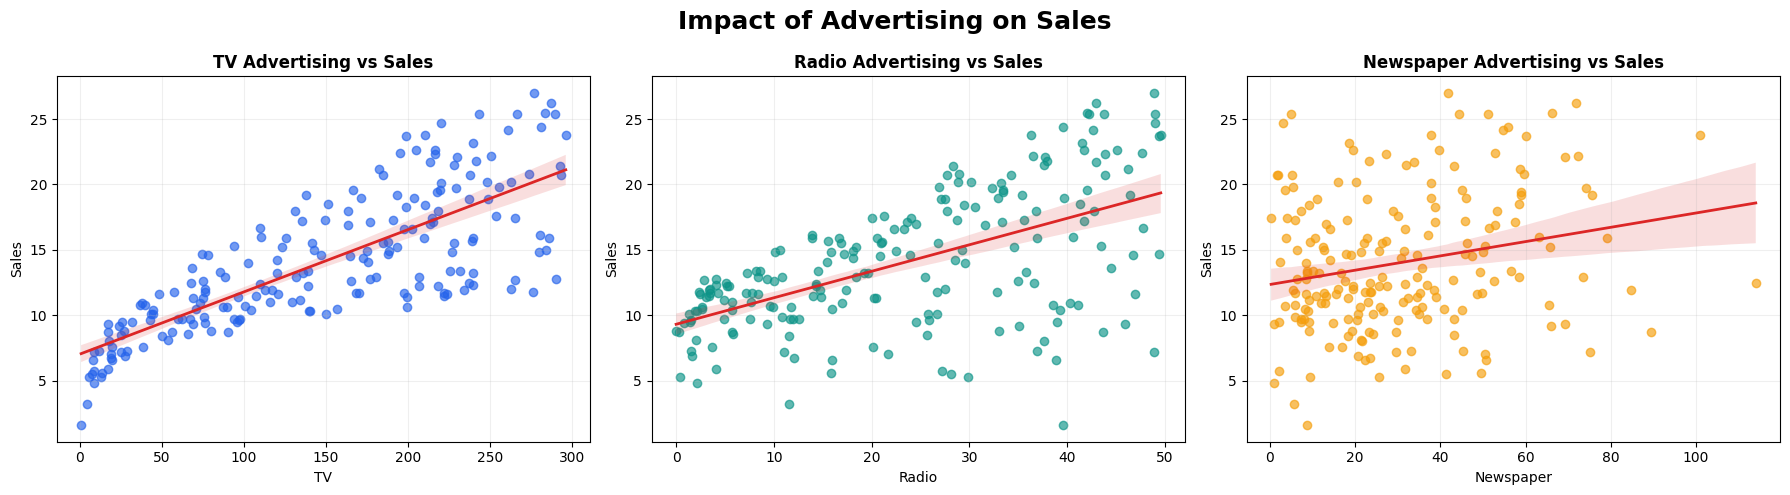

In [103]:

# ADVERTISING IMPACT ON SALES

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

features = ["TV", "Radio", "Newspaper"]
colors = ["#2563EB", "#0D9488", "#F59E0B"]

for ax, feature, color in zip(axes, features, colors):
    sns.regplot(
        data=df,
        x=feature,
        y="Sales",
        ax=ax,
        scatter_kws={"alpha": 0.65, "color": color},
        line_kws={"color": "#DC2626", "linewidth": 2}
    )
    ax.set_title(f"{feature} Advertising vs Sales", fontweight="bold")
    ax.grid(alpha=0.2)

plt.suptitle(
    "Impact of Advertising on Sales",
    fontsize=18,
    fontweight="bold"
)
plt.tight_layout()
plt.show()

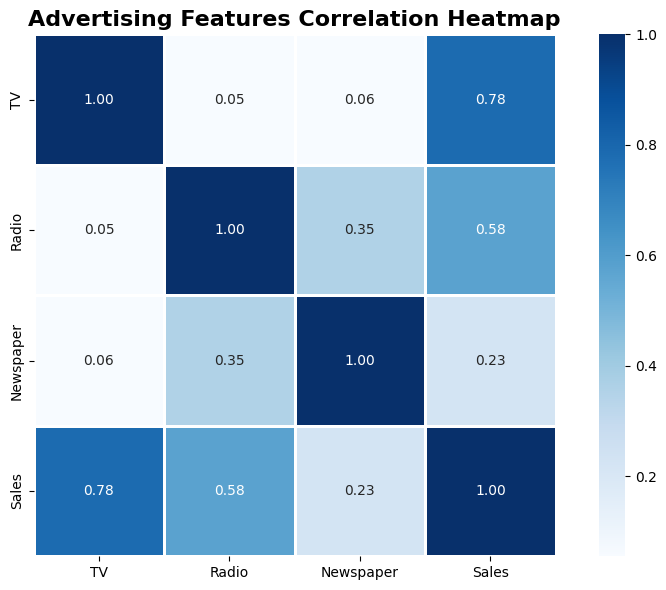

In [88]:

# CORRELATION HEATMAP

plt.figure(figsize=(9, 6))

correlation = df[["TV", "Radio", "Newspaper", "Sales"]].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="Blues",
    fmt=".2f",
    linewidths=1,
    square=True
)

plt.title(
    "Advertising Features Correlation Heatmap",
    fontsize=16,
    fontweight="bold"
)
plt.tight_layout()
plt.show()

In [89]:

# TRAIN LINEAR REGRESSION MODEL

X = df[["TV", "Radio", "Newspaper"]]
y = df["Sales"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Model trained successfully!")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Model trained successfully!
Training records: 160
Testing records: 40


In [90]:

# MODEL PERFORMANCE

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("=" * 45)
print("       MODEL PERFORMANCE REPORT")
print("=" * 45)
print(f"Mean Absolute Error (MAE): {mae:.3f}")
print(f"Mean Squared Error (MSE):  {mse:.3f}")
print(f"Root Mean Squared Error:   {rmse:.3f}")
print(f"R² Score:                  {r2:.3f}")
print("=" * 45)

       MODEL PERFORMANCE REPORT
Mean Absolute Error (MAE): 1.461
Mean Squared Error (MSE):  3.174
Root Mean Squared Error:   1.782
R² Score:                  0.899


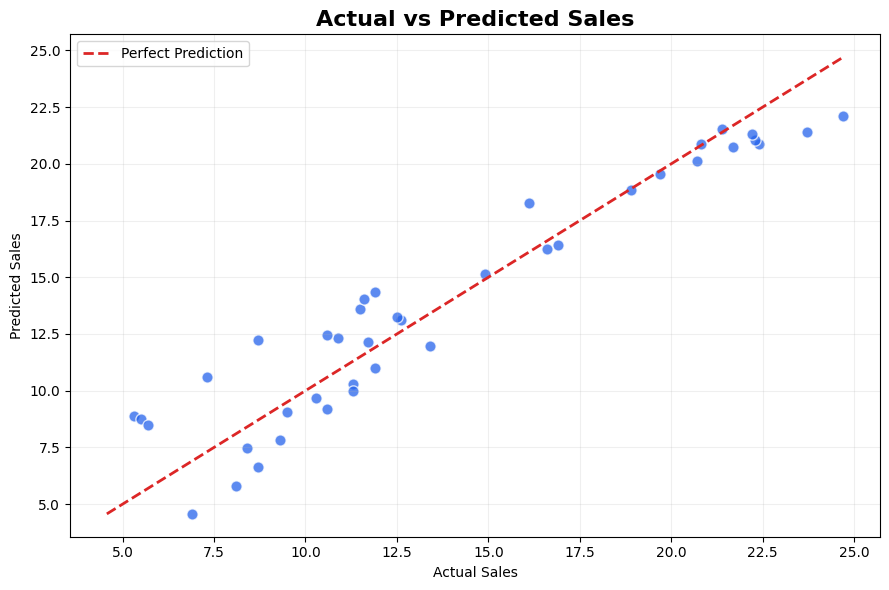

In [91]:

# ACTUAL VS PREDICTED SALES

plt.figure(figsize=(9, 6))

plt.scatter(
    y_test, y_pred,
    color="#2563EB",
    alpha=0.75,
    s=65,
    edgecolor="white"
)

min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "--",
    color="#DC2626",
    linewidth=2,
    label="Perfect Prediction"
)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales", fontsize=16, fontweight="bold")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

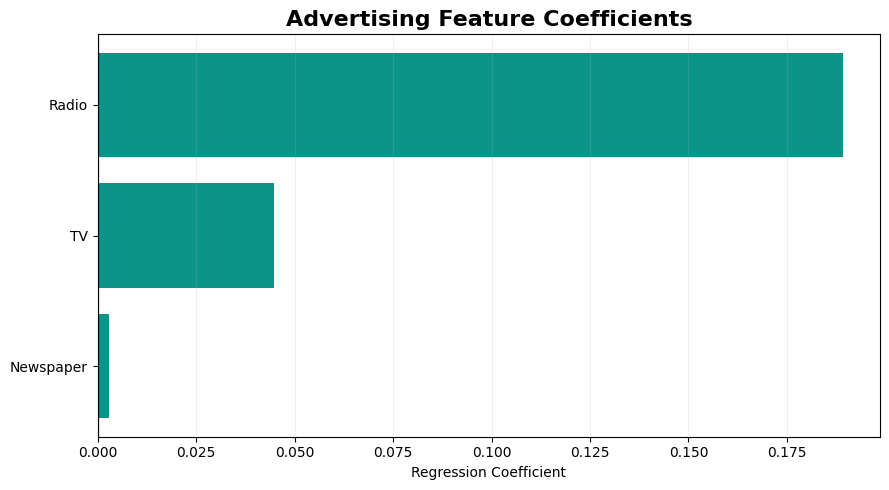

,Feature,Coefficient
1,Radio,0.189195
0,TV,0.044730
2,Newspaper,0.002761


In [92]:

# FEATURE IMPORTANCE

importance = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

importance = importance.sort_values(
    "Coefficient", ascending=True
)

plt.figure(figsize=(9, 5))

colors = [
    "#0D9488" if value >= 0 else "#DC2626"
    for value in importance["Coefficient"]
]

plt.barh(
    importance["Feature"],
    importance["Coefficient"],
    color=colors
)

plt.axvline(0, color="black", linewidth=0.8)
plt.title("Advertising Feature Coefficients", fontsize=16, fontweight="bold")
plt.xlabel("Regression Coefficient")
plt.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

display(importance.sort_values("Coefficient", ascending=False))

In [93]:

# PREDICT SALES FOR CUSTOM ADVERTISING BUDGETS

from IPython.display import display, clear_output
import ipywidgets as widgets

tv_input = widgets.FloatSlider(
    value=150, min=0, max=300, step=5,
    description="TV:", style={"description_width": "80px"},
    layout=widgets.Layout(width="450px")
)

radio_input = widgets.FloatSlider(
    value=25, min=0, max=50, step=1,
    description="Radio:", style={"description_width": "80px"},
    layout=widgets.Layout(width="450px")
)

newspaper_input = widgets.FloatSlider(
    value=20, min=0, max=120, step=5,
    description="Newspaper:", style={"description_width": "80px"},
    layout=widgets.Layout(width="450px")
)

predict_button = widgets.Button(
    description="Predict Sales",
    button_style="primary",
    icon="check"
)

output = widgets.Output()

def predict_sales(button):
    with output:
        clear_output(wait=True)

        new_data = pd.DataFrame([{
            "TV": tv_input.value,
            "Radio": radio_input.value,
            "Newspaper": newspaper_input.value
        }])

        prediction = model.predict(new_data)[0]

        display(HTML(f"""
        <div style="background:linear-gradient(135deg,#102A43,#2563EB);
        padding:22px;border-radius:14px;color:white;font-family:Arial;">
            <div style="font-size:15px;">PREDICTED SALES</div>
            <div style="font-size:34px;font-weight:bold;margin-top:8px;">
                {prediction:.2f}
            </div>
            <div style="font-size:12px;margin-top:8px;">
                Estimate from your trained Linear Regression model
            </div>
        </div>
        """))

predict_button.on_click(predict_sales)

display(HTML("""
<h3 style="color:#17365D;">🔮 Try Your Own Advertising Budget</h3>
<p>Adjust the sliders and click Predict Sales.</p>
"""))

display(tv_input, radio_input, newspaper_input, predict_button, output)

FloatSlider(value=150.0, description='TV:', layout=Layout(width='450px'), max=300.0, step=5.0, style=SliderSty…

FloatSlider(value=25.0, description='Radio:', layout=Layout(width='450px'), max=50.0, step=1.0, style=SliderSt…

FloatSlider(value=20.0, description='Newspaper:', layout=Layout(width='450px'), max=120.0, step=5.0, style=Sli…

Button(button_style='primary', description='Predict Sales', icon='check', style=ButtonStyle())

Output()

In [94]:

!pip -q install gradio

import gradio as gr
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Libraries ready!")

Libraries ready!


In [105]:

# INFOZATECH TASK 4
# SALES PREDICTION DASHBOARD

import gradio as gr
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# -------------------------------
# 1. PREPARE DATA AND MODEL
# -------------------------------

# Remove an unnecessary index column if present
df = df.loc[:, ~df.columns.astype(str).str.startswith("Unnamed")].copy()

features = ["TV", "Radio", "Newspaper"]
X = df[features]
y = df["Sales"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# -------------------------------
# 2. DASHBOARD CHARTS
# -------------------------------

def sales_distribution():
    fig, ax = plt.subplots(figsize=(7, 4))
    sns.histplot(
        data=df, x="Sales", bins=20, kde=True,
        color="#2563EB", ax=ax
    )
    ax.set_title("Sales Distribution", fontsize=14, fontweight="bold")
    ax.set_xlabel("Sales")
    ax.set_ylabel("Frequency")
    ax.grid(axis="y", alpha=0.2)
    fig.tight_layout()
    return fig


def advertising_scatter(feature):
    fig, ax = plt.subplots(figsize=(7, 4))
    sns.regplot(
        data=df, x=feature, y="Sales", ax=ax,
        scatter_kws={"alpha": 0.65, "color": "#2563EB"},
        line_kws={"color": "#EF4444", "linewidth": 2}
    )
    ax.set_title(f"{feature} Advertising vs Sales",
                 fontsize=14, fontweight="bold")
    ax.grid(alpha=0.2)
    fig.tight_layout()
    return fig


def correlation_heatmap():
    fig, ax = plt.subplots(figsize=(7, 5))
    sns.heatmap(
        df[features + ["Sales"]].corr(),
        annot=True, cmap="Blues", fmt=".2f",
        linewidths=1, ax=ax
    )
    ax.set_title("Advertising Correlation Heatmap",
                 fontsize=14, fontweight="bold")
    fig.tight_layout()
    return fig


def actual_vs_predicted():
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.scatter(
        y_test, y_pred, color="#2563EB",
        alpha=0.75, s=60, edgecolor="white"
    )

    lower = min(float(y_test.min()), float(np.min(y_pred)))
    upper = max(float(y_test.max()), float(np.max(y_pred)))

    ax.plot(
        [lower, upper], [lower, upper],
        "--", color="#EF4444", label="Perfect prediction"
    )
    ax.set_xlabel("Actual Sales")
    ax.set_ylabel("Predicted Sales")
    ax.set_title("Actual vs Predicted Sales",
                 fontsize=14, fontweight="bold")
    ax.legend()
    ax.grid(alpha=0.2)
    fig.tight_layout()
    return fig


def feature_coefficients():
    importance = pd.DataFrame({
        "Feature": features,
        "Coefficient": model.coef_
    }).sort_values("Coefficient", ascending=True)

    fig, ax = plt.subplots(figsize=(7, 4))
    colors = [
        "#0D9488" if value >= 0 else "#EF4444"
        for value in importance["Coefficient"]
    ]

    ax.barh(
        importance["Feature"],
        importance["Coefficient"],
        color=colors
    )
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xlabel("Regression Coefficient")
    ax.set_title("Advertising Feature Coefficients",
                 fontsize=14, fontweight="bold")
    ax.grid(axis="x", alpha=0.2)
    fig.tight_layout()
    return fig


# -------------------------------
# 3. SALES PREDICTION FUNCTION
# -------------------------------

def predict_sales(tv, radio, newspaper):
    new_data = pd.DataFrame([{
        "TV": tv,
        "Radio": radio,
        "Newspaper": newspaper
    }])

    prediction = float(model.predict(new_data)[0])

    return (
        f"Estimated Sales: {prediction:.2f}",
        {
            "TV": float(tv),
            "Radio": float(radio),
            "Newspaper": float(newspaper)
        }
    )


# -------------------------------
# 4. BUILD THE GRADIO DASHBOARD
# -------------------------------

custom_css = """
.gradio-container {
    background: #F1F5F9 !important;
}
#main-header {
    background: linear-gradient(135deg, #102A43, #2563EB);
    color: white;
    padding: 24px;
    border-radius: 16px;
    text-align: center;
}
.metric-card {
    background: white;
    border-radius: 12px;
    padding: 16px;
    text-align: center;
    border: 1px solid #DBEAFE;
}
"""

with gr.Blocks(
    title="InfozaTech Sales Prediction"
) as demo:

    gr.HTML("""
    <div id="main-header">
        <h1>📊 Sales Prediction Dashboard</h1>
        <p>INFOZATECH | Data Science Internship — Task 4</p>
        <p>Advertising Analytics & Machine Learning</p>
    </div>
    """)

    gr.Markdown("## 📌 Project Overview")

    with gr.Row():
        gr.Number(
            value=len(df),
            label="Dataset Records",
            interactive=False
        )
        gr.Number(
            value=len(features),
            label="Advertising Features",
            interactive=False
        )
        gr.Number(
            value=round(r2 * 100, 2),
            label="R² Score (%)",
            interactive=False
        )
        gr.Number(
            value=round(mae, 3),
            label="Mean Absolute Error",
            interactive=False
        )

    with gr.Tabs():

        # DATASET TAB
        with gr.Tab("📁 Dataset"):
            gr.Markdown("### Advertising Dataset Preview")
            gr.Dataframe(
                value=df.head(10),
                interactive=False
            )

            gr.Markdown("### Statistical Summary")
            gr.Dataframe(
                value=df[features + ["Sales"]].describe().round(2),
                interactive=False
            )

            gr.Plot(value=sales_distribution)

        # VISUALIZATION TAB
        with gr.Tab("📈 Visualizations"):
            gr.Markdown("### Advertising Channels vs Sales")

            with gr.Row():
                gr.Plot(value=lambda: advertising_scatter("TV"))
                gr.Plot(value=lambda: advertising_scatter("Radio"))

            with gr.Row():
                gr.Plot(value=lambda: advertising_scatter("Newspaper"))
                gr.Plot(value=correlation_heatmap)

        # MODEL PERFORMANCE TAB
        with gr.Tab("🤖 Model Performance"):
            gr.Markdown("### Linear Regression Evaluation")

            gr.Dataframe(
                value=pd.DataFrame({
                    "Metric": ["MAE", "MSE", "RMSE", "R² Score"],
                    "Value": [mae, mse, rmse, r2]
                }).round(4),
                interactive=False
            )

            gr.Plot(value=actual_vs_predicted)

            gr.Markdown("### Advertising Feature Coefficients")
            gr.Plot(value=feature_coefficients)

        # PREDICTION TAB
        with gr.Tab("🔮 Predict Sales"):
            gr.Markdown("""
            ### Try Your Own Advertising Budget
            Adjust the sliders and click **Predict Sales**.
            The model will estimate sales from your inputs.
            """)

            tv = gr.Slider(
                minimum=0, maximum=300, value=150,
                step=1, label="TV Advertising Budget"
            )

            radio = gr.Slider(
                minimum=0, maximum=50, value=25,
                step=1, label="Radio Advertising Budget"
            )

            newspaper = gr.Slider(
                minimum=0, maximum=120, value=20,
                step=1, label="Newspaper Advertising Budget"
            )

            predict_button = gr.Button(
                "🔮 Predict Sales",
                variant="primary"
            )

            result = gr.Textbox(label="Predicted Sales Result")

            budget_output = gr.JSON(label="Input Advertising Budgets")

            predict_button.click(
                fn=predict_sales,
                inputs=[tv, radio, newspaper],
                outputs=[result, budget_output]
            )

    gr.Markdown("""
    ---
    **Conclusion:** This project uses exploratory data analysis,
    data visualization, and Linear Regression to estimate sales
    from advertising expenditure.

    *Developed for the InfozaTech Data Science Internship.*
    """)

demo.launch(
    share=True,
    theme=gr.themes.Soft(
        primary_hue="blue",
        secondary_hue="cyan"
    ),
    css=custom_css
)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://7e657c15b52344cd30.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [96]:

# STEP 13: SAVE A STATIC PREDICTION RESULT FOR GITHUB

example_input = pd.DataFrame([{
    "TV": 150,
    "Radio": 25,
    "Newspaper": 20
}])

example_prediction = model.predict(example_input)[0]

print("=" * 45)
print("       SALES PREDICTION RESULT")
print("=" * 45)
print("TV advertising budget:        150")
print("Radio advertising budget:      25")
print("Newspaper advertising budget:  20")
print(f"Predicted sales: {example_prediction:.2f}")
print("=" * 45)

       SALES PREDICTION RESULT
TV advertising budget:        150
Radio advertising budget:      25
Newspaper advertising budget:  20
Predicted sales: 14.47


In [97]:

from IPython.display import display, HTML

display(HTML("""
<div style="
background:linear-gradient(135deg,#102A43,#2563EB);
padding:25px;border-radius:15px;color:white;font-family:Arial;
">
<h2>📌 Project Conclusion</h2>
<p>
This project explored the relationship between advertising expenditure
and sales using Python.
</p>
<ul>
<li>Analyzed TV, Radio, and Newspaper advertising data.</li>
<li>Created visualizations and a correlation heatmap.</li>
<li>Trained a Linear Regression model.</li>
<li>Evaluated the model using MAE, MSE, RMSE, and R² score.</li>
<li>Built an interactive sales prediction tool.</li>
</ul>
<p>
The model estimates sales from advertising budgets. Its predictions
should be interpreted alongside the evaluation metrics.
</p>
</div>
"""))

# Task 4: Sales Prediction Using Advertising Data

## Objective

The objective of this project is to predict sales based on advertising expenditure across TV, Radio, and Newspaper channels using machine learning.

## Tools and Technologies

* Python
* Pandas and NumPy
* Matplotlib and Seaborn
* Scikit-learn
* Google Colab
* GitHub

## Project Implementation

1. Loaded and explored the advertising dataset.
2. Examined dataset information, descriptive statistics, and missing values.
3. Created a professional dashboard with summary cards.
4. Visualized sales distribution using a histogram.
5. Analyzed the relationship between advertising expenditure and sales using scatter plots and regression lines.
6. Created a correlation heatmap to understand relationships between variables.
7. Trained a Linear Regression model using training and testing datasets.
8. Evaluated model performance using MAE, MSE, RMSE, and R² score.
9. Compared actual sales with predicted sales using a visualization.
10. Displayed regression coefficients to analyze advertising features.
11. Developed an interactive tool to predict sales based on user-provided advertising budgets.

## Outcome

Developed a Sales Prediction project that combines data analysis, visualization, and machine learning to estimate sales from advertising expenditure.

## Conclusion

This project provided practical experience in exploratory data analysis, data visualization, regression modelling, model evaluation, and interactive predictions using Python.

**Project:** InfozaTech Data Science Internship — Task 4
